In [ ]:
# import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
!pip install pandas scikit-learn
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [ ]:
# Load data from CSV file
df = pd.read_csv('/content/MACHINE DOWNTIME-DATASET.csv')

In [ ]:
# To know the no. of rows and columns of the dataset
df.shape

(2500, 18)

In [ ]:
# Inspect data
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 18 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Date                             2500 non-null   object 
 1   Machine_ID                       2500 non-null   object 
 2   Assembly_Line_No                 2500 non-null   object 
 3   Hydraulic_Pressure(bar)          2490 non-null   float64
 4   Coolant_Pressure(bar)            2481 non-null   float64
 5   Air_System_Pressure(bar)         2483 non-null   float64
 6   Coolant_Temperature              2488 non-null   float64
 7   Hydraulic_Oil_Temperature(°C)    2484 non-null   float64
 8   Spindle_Bearing_Temperature(°C)  2493 non-null   float64
 9   Spindle_Vibration(µm)            2489 non-null   float64
 10  Tool_Vibration(µm)               2489 non-null   float64
 11  Spindle_Speed(RPM)               2494 non-null   float64
 12  Voltage(volts)      

In [ ]:
df.describe()

,Hydraulic_Pressure(bar),Coolant_Pressure(bar),Air_System_Pressure(bar),Coolant_Temperature,Hydraulic_Oil_Temperature(°C),Spindle_Bearing_Temperature(°C),Spindle_Vibration(µm),Tool_Vibration(µm),Spindle_Speed(RPM),Voltage(volts),Torque(Nm),Cutting(kN),Unnamed: 16,Unnamed: 17
count,2490.000000,2481.000000,2483.000000,2488.000000,2484.000000,2493.000000,2489.000000,2489.000000,2494.000000,2494.000000,2479.00000,2493.000000,0.0,1.00
mean,101.420739,4.947175,6.499340,18.559887,47.618317,35.063698,1.010185,25.411975,20274.792302,348.996792,25.23451,2.782551,NaN,252537.64
std,30.250627,0.996917,0.407347,8.554480,3.768674,3.764823,0.341849,6.437142,3852.660056,45.376024,6.13828,0.616688,NaN,NaN
min,14.330000,0.330000,5.060000,4.100000,35.200000,22.600000,0.010000,2.161000,0.000000,202.000000,0.00000,1.800000,NaN,252537.64
25%,76.355000,4.460000,6.220000,10.400000,45.100000,32.500000,0.780000,21.089000,17919.000000,319.000000,21.66500,2.250000,NaN,252537.64
50%,96.765000,4.940000,6.510000,21.200000,47.700000,35.100000,1.010000,25.455000,20137.500000,349.000000,24.65000,2.780000,NaN,252537.64
75%,126.415000,5.520000,6.780000,25.600000,50.100000,37.600000,1.240000,29.790000,22501.750000,380.000000,30.51000,3.270000,NaN,252537.64
max,191.000000,11.350000,7.970000,98.200000,61.400000,49.500000,2.000000,45.726000,27957.000000,479.000000,55.55000,3.930000,NaN,252537.64


In [ ]:

# To see first 5 datapoints
df.head()

,Date,Machine_ID,Assembly_Line_No,Hydraulic_Pressure(bar),Coolant_Pressure(bar),Air_System_Pressure(bar),Coolant_Temperature,Hydraulic_Oil_Temperature(°C),Spindle_Bearing_Temperature(°C),Spindle_Vibration(µm),Tool_Vibration(µm),Spindle_Speed(RPM),Voltage(volts),Torque(Nm),Cutting(kN),Downtime,Unnamed: 16,Unnamed: 17
0,31-12-2021,Makino-L1-Unit1-2013,Shopfloor-L1,71.04,6.93,6.28,25.6,46.0,33.4,1.29,26.492,25892.0,335.0,24.06,3.58,Machine_Failure,NaN,NaN
1,31-12-2021,Makino-L1-Unit1-2013,Shopfloor-L1,125.33,4.94,6.20,35.3,47.4,34.6,1.38,25.274,19856.0,368.0,14.20,2.68,Machine_Failure,NaN,NaN
2,31-12-2021,Makino-L3-Unit1-2015,Shopfloor-L3,71.12,6.84,6.66,13.1,40.7,33.0,1.32,30.608,19851.0,325.0,24.05,3.55,Machine_Failure,NaN,NaN
3,31-05-2022,Makino-L2-Unit1-2015,Shopfloor-L2,139.34,4.57,6.56,24.4,44.2,40.6,0.62,30.791,18461.0,360.0,25.86,3.55,Machine_Failure,NaN,252537.64
4,31-03-2022,Makino-L1-Unit1-2013,Shopfloor-L1,60.51,6.89,6.14,4.1,47.3,31.4,0.98,25.516,26526.0,354.0,25.52,3.55,Machine_Failure,NaN,NaN


In [ ]:
# To see last 5 datapoints
df.tail()

,Date,Machine_ID,Assembly_Line_No,Hydraulic_Pressure(bar),Coolant_Pressure(bar),Air_System_Pressure(bar),Coolant_Temperature,Hydraulic_Oil_Temperature(°C),Spindle_Bearing_Temperature(°C),Spindle_Vibration(µm),Tool_Vibration(µm),Spindle_Speed(RPM),Voltage(volts),Torque(Nm),Cutting(kN),Downtime,Unnamed: 16,Unnamed: 17
2495,01-02-2022,Makino-L1-Unit1-2013,Shopfloor-L1,112.72,5.22,6.20,22.3,48.8,37.2,0.91,20.282,20974.0,282.0,22.76,2.72,No_Machine_Failure,NaN,NaN
2496,01-02-2022,Makino-L1-Unit1-2013,Shopfloor-L1,103.09,5.21,7.07,11.9,48.3,31.5,1.11,34.708,20951.0,319.0,22.79,2.94,No_Machine_Failure,NaN,NaN
2497,01-02-2022,Makino-L2-Unit1-2015,Shopfloor-L2,118.64,5.21,6.53,4.5,49.9,36.2,0.29,16.828,20958.0,335.0,22.78,NaN,No_Machine_Failure,NaN,NaN
2498,01-02-2022,Makino-L3-Unit1-2015,Shopfloor-L3,145.86,5.21,6.40,12.2,44.5,32.1,1.00,26.498,20935.0,376.0,22.80,2.79,No_Machine_Failure,NaN,NaN
2499,01-02-2022,Makino-L2-Unit1-2015,Shopfloor-L2,96.69,5.94,7.11,29.8,53.2,36.2,0.84,31.580,23576.0,385.0,24.41,3.55,Machine_Failure,NaN,NaN


In [ ]:
#Checking for any null values in dataset
df.isnull().sum()

,0
Date,0
Machine_ID,0
Assembly_Line_No,0
Hydraulic_Pressure(bar),10
Coolant_Pressure(bar),19
Air_System_Pressure(bar),17
Coolant_Temperature,12
Hydraulic_Oil_Temperature(°C),16
Spindle_Bearing_Temperature(°C),7
Spindle_Vibration(µm),11


In [ ]:
# Identify columns with null values
null_columns = df.columns[df.isnull().any()]
print("Columns with null values:")
print(null_columns)

Columns with null values:
Index(['Hydraulic_Pressure(bar)', 'Coolant_Pressure(bar)',
       'Air_System_Pressure(bar)', 'Coolant_Temperature',
       'Hydraulic_Oil_Temperature(°C)', 'Spindle_Bearing_Temperature(°C)',
       'Spindle_Vibration(µm)', 'Tool_Vibration(µm)', 'Spindle_Speed(RPM)',
       'Voltage(volts)', 'Torque(Nm)', 'Cutting(kN)', 'Unnamed: 16',
       'Unnamed: 17'],
      dtype='object')


In [ ]:
# Remove columns with null values
df_cleaned = df.dropna(axis=1)

In [ ]:
print("Data types of each column:")
print(df_cleaned.dtypes)

Data types of each column:
Date                object
Machine_ID          object
Assembly_Line_No    object
Downtime            object
dtype: object


In [ ]:
# Check the contents
print(df_cleaned.head())

         Date            Machine_ID Assembly_Line_No         Downtime
0  31-12-2021  Makino-L1-Unit1-2013     Shopfloor-L1  Machine_Failure
1  31-12-2021  Makino-L1-Unit1-2013     Shopfloor-L1  Machine_Failure
2  31-12-2021  Makino-L3-Unit1-2015     Shopfloor-L3  Machine_Failure
3  31-05-2022  Makino-L2-Unit1-2015     Shopfloor-L2  Machine_Failure
4  31-03-2022  Makino-L1-Unit1-2013     Shopfloor-L1  Machine_Failure


In [ ]:
# Identify removed columns
removed_columns = set(null_columns) - set(df_cleaned.columns)
print("Removed Columns with null values:")
print(removed_columns)

Removed Columns with null values:
{'Torque(Nm)', 'Voltage(volts)', 'Coolant_Temperature', 'Unnamed: 17', 'Spindle_Speed(RPM)', 'Hydraulic_Oil_Temperature(°C)', 'Cutting(kN)', 'Spindle_Bearing_Temperature(°C)', 'Coolant_Pressure(bar)', 'Spindle_Vibration(µm)', 'Hydraulic_Pressure(bar)', 'Tool_Vibration(µm)', 'Air_System_Pressure(bar)', 'Unnamed: 16'}


In [ ]:
# Fill null values with 0
df_filled = df.fillna(0)

In [ ]:
# Check if there are any null values left in the DataFrame
null_check = df_filled.isnull().any().any()

if not null_check:
    print("All null values have been successfully filled with 0.")
else:
    print("There are still some null values in the DataFrame.")

All null values have been successfully filled with 0.


In [ ]:
#Checking for Duplicates
df.duplicated().sum()

0

In [ ]:
#Removing Duplicates
df=df.drop_duplicates()

In [ ]:
# Check for any remaining null values in each column
remaining_nulls = df_filled.isnull().sum()

print("Null values count after filling:")
print(remaining_nulls)

Null values count after filling:
Date                               0
Machine_ID                         0
Assembly_Line_No                   0
Hydraulic_Pressure(bar)            0
Coolant_Pressure(bar)              0
Air_System_Pressure(bar)           0
Coolant_Temperature                0
Hydraulic_Oil_Temperature(°C)      0
Spindle_Bearing_Temperature(°C)    0
Spindle_Vibration(µm)              0
Tool_Vibration(µm)                 0
Spindle_Speed(RPM)                 0
Voltage(volts)                     0
Torque(Nm)                         0
Cutting(kN)                        0
Downtime                           0
Unnamed: 16                        0
Unnamed: 17                        0
dtype: int64


In [ ]:
# Check for duplicates
# Identifying duplicate rows
duplicates = df[df.duplicated()]

In [ ]:
# Removing duplicate rows
df_cleaned = df.drop_duplicates()

In [ ]:
# Print the duplicate rows
print("Duplicate Rows:")
print(duplicates)

Duplicate Rows:
Empty DataFrame
Columns: [Date, Machine_ID, Assembly_Line_No, Hydraulic_Pressure(bar), Coolant_Pressure(bar), Air_System_Pressure(bar), Coolant_Temperature, Hydraulic_Oil_Temperature(°C), Spindle_Bearing_Temperature(°C), Spindle_Vibration(µm), Tool_Vibration(µm), Spindle_Speed(RPM), Voltage(volts), Torque(Nm), Cutting(kN), Downtime, Unnamed: 16, Unnamed: 17]
Index: []


In [ ]:
# Inference: Descriptive statistics provide a summary of key metrics for each numerical column in your dataset.
# This information is crucial for understanding the central tendencies, variability, and overall distribution of our data.

# Get descriptive statistics
print("\nDescriptive Statistics:")
print(df_cleaned.describe())


Descriptive Statistics:
       Hydraulic_Pressure(bar)  Coolant_Pressure(bar)  \
count              2490.000000            2481.000000   
mean                101.420739               4.947175   
std                  30.250627               0.996917   
min                  14.330000               0.330000   
25%                  76.355000               4.460000   
50%                  96.765000               4.940000   
75%                 126.415000               5.520000   
max                 191.000000              11.350000   

       Air_System_Pressure(bar)  Coolant_Temperature  \
count               2483.000000          2488.000000   
mean                   6.499340            18.559887   
std                    0.407347             8.554480   
min                    5.060000             4.100000   
25%                    6.220000            10.400000   
50%                    6.510000            21.200000   
75%                    6.780000            25.600000   
max          

In [ ]:
# Inference : Focus on Numeric Columns: Many data preprocessing techniques, like scaling, normalization, and statistical analyses,
# are typically applied to numeric data. Exclude Non-Numeric Data

# Select numeric features for scaling
numeric_features = df_cleaned.select_dtypes(include=['float64', 'int64']).columns

In [ ]:
# Inference : Standardization transforms numeric features to have a mean of 0 and a standard deviation of 1.
# This ensures consistent scaling, improving model performance and analysis accuracy.

# Standardization (Z-score normalization)
scaler_standard = StandardScaler()
df_standard_scaled = df_cleaned.copy()
df_standard_scaled[numeric_features] = scaler_standard.fit_transform(df_cleaned[numeric_features])

/usr/local/lib/python3.10/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.10/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.10/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


In [ ]:
# Inference : Min-Max Scaling resizes numeric features to a range, usually 0 to 1.
# This balances the scale of all features for better model performance.

# Min-Max Scaling
scaler_minmax = MinMaxScaler()
df_minmax_scaled = df_cleaned.copy()
df_minmax_scaled[numeric_features] = scaler_minmax.fit_transform(df_cleaned[numeric_features])
# Print scaled data
print("Standardized Data (first 5 rows):")
print(df_standard_scaled.head())


Standardized Data (first 5 rows):
         Date            Machine_ID Assembly_Line_No  Hydraulic_Pressure(bar)  \
0  31-12-2021  Makino-L1-Unit1-2013     Shopfloor-L1                -1.004503   
1  31-12-2021  Makino-L1-Unit1-2013     Shopfloor-L1                 0.790531   
2  31-12-2021  Makino-L3-Unit1-2015     Shopfloor-L3                -1.001858   
3  31-05-2022  Makino-L2-Unit1-2015     Shopfloor-L2                 1.253755   
4  31-03-2022  Makino-L1-Unit1-2013     Shopfloor-L1                -1.352665   

   Coolant_Pressure(bar)  Air_System_Pressure(bar)  Coolant_Temperature  \
0               1.989358                 -0.538568             0.823139   
1              -0.007198                 -0.735000             1.957276   
2               1.899062                  0.394487            -0.638377   
3              -0.378417                  0.148946             0.682834   
4               1.949227                 -0.882325            -1.690669   

   Hydraulic_Oil_Temperature

/usr/local/lib/python3.10/dist-packages/sklearn/utils/_array_api.py:769: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
/usr/local/lib/python3.10/dist-packages/sklearn/utils/_array_api.py:786: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))


DATA VISUALIZATION :

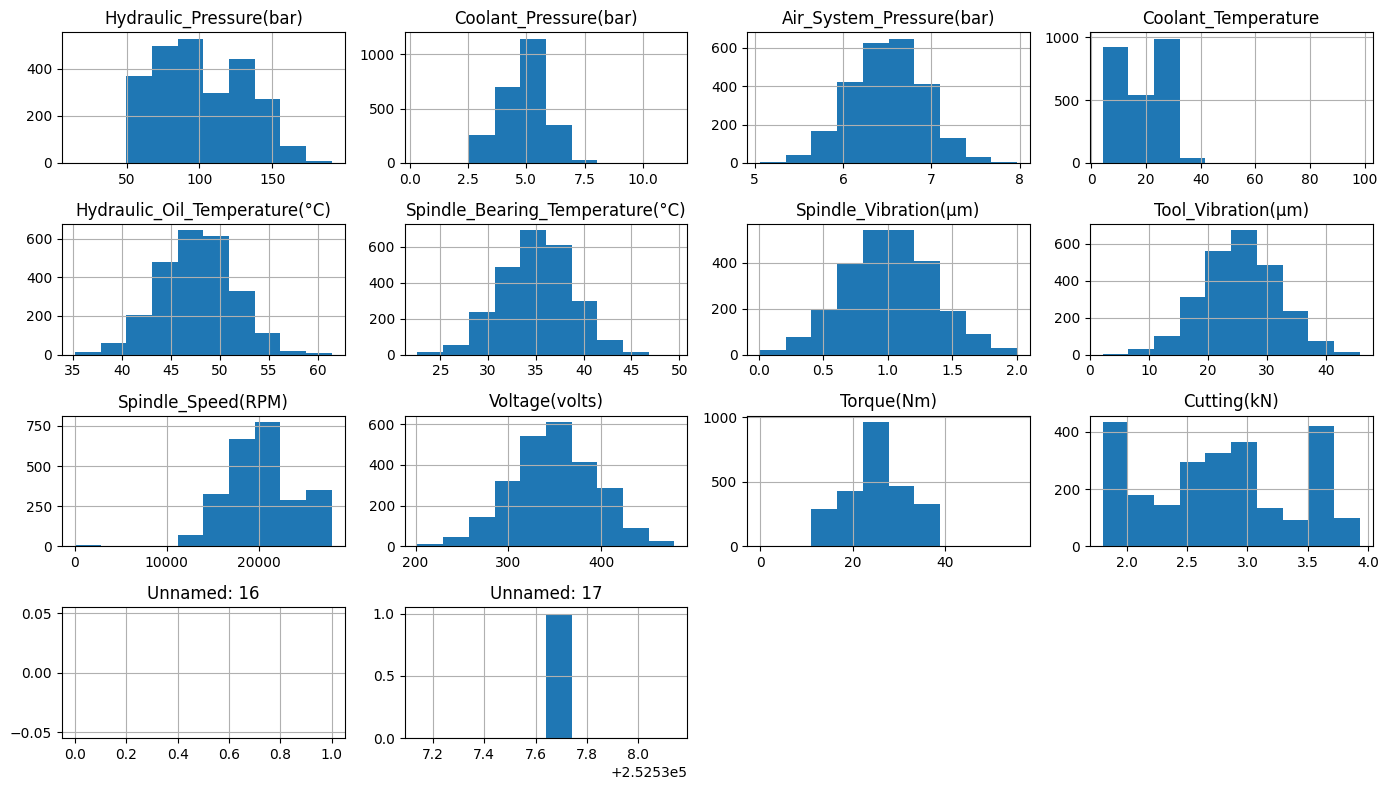

In [ ]:
# visualize data distribution
# Histogram
# Inference : Histograms display how data points are distributed across different ranges and
# they help visualize the shape, spread, and central tendency of the data.

# Plot histograms for numerical features
df_cleaned.hist(figsize=(14, 8))
plt.tight_layout()
plt.show()


In [ ]:
# Inference : It measures the strength and direction of the linear relationship between two variables for model- building process.
# The value ranges from -1 to 1.
# Positive Correlation: A value closer to 1 indicates a strong positive relationship.
# Negative Correlation: A value closer to -1 indicates a strong negative relationship.
# Near Zero: Values near zero indicate no linear relationship.

# Define numeric_df
numeric_df = df_cleaned.select_dtypes(include=['float64', 'int64'])
# Calculate correlation matrix
corr_matrix = numeric_df.corr()
# Print the correlation matrix
print("Correlation Matrix:")
print(corr_matrix)

Correlation Matrix:
                                 Hydraulic_Pressure(bar)  \
Hydraulic_Pressure(bar)                         1.000000   
Coolant_Pressure(bar)                          -0.074718   
Air_System_Pressure(bar)                       -0.030050   
Coolant_Temperature                            -0.112014   
Hydraulic_Oil_Temperature(°C)                   0.008860   
Spindle_Bearing_Temperature(°C)                 0.022937   
Spindle_Vibration(µm)                          -0.004980   
Tool_Vibration(µm)                              0.020514   
Spindle_Speed(RPM)                             -0.120538   
Voltage(volts)                                 -0.004029   
Torque(Nm)                                      0.163503   
Cutting(kN)                                    -0.222538   
Unnamed: 16                                          NaN   
Unnamed: 17                                          NaN   

                                 Coolant_Pressure(bar)  \
Hydraulic_Pressure(ba

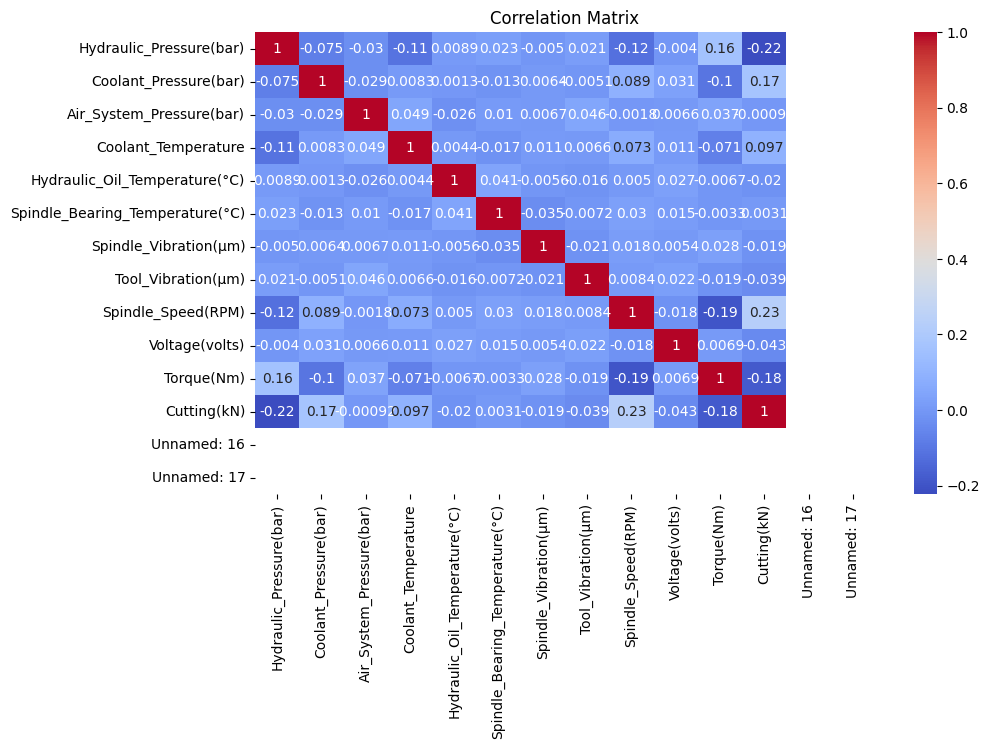

In [ ]:
# Inference : The heatmap visualizes the correlation matrix, showing the strength and direction of relationships between variables using color gradients.
# This makes it easy to identify strong positive, negative, or weak correlations at a glance.

# Plot the heatmap of the correlation matrix
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


ValueError: List of boxplot statistics and `positions` values must have same the length

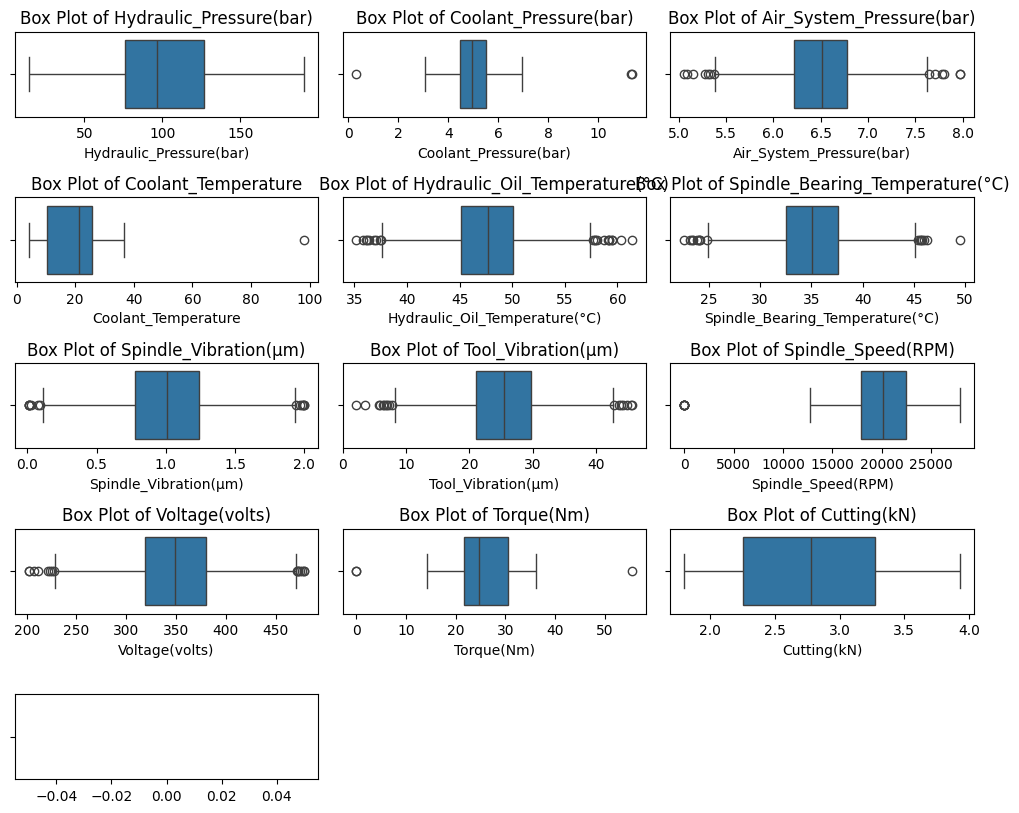

In [ ]:
# Inference : A box plot visualizes the distribution of a dataset by showing its minimum, first quartile, median, third quartile,
# and maximum. It helps identify outliers, the spread, and the central tendency of the data.

# Identify and Handle Outliers
# Create box plots for numerical features to identify outliers
numerical_features = df_cleaned.select_dtypes(include=['float64', 'int64']).columns

plt.figure(figsize=(10, 8))
for i, feature in enumerate(numerical_features, 1):
    plt.subplot(len(numerical_features)//3 + 1, 3, i)
    sns.boxplot(data=df_cleaned, x=feature)
    plt.title(f'Box Plot of {feature}')
    plt.tight_layout()
plt.show()


KeyError: 'Hydraulic_Pressure(bar)'

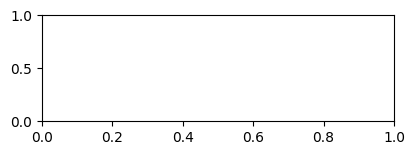

In [ ]:
# Inference : Histograms display the frequency distribution of data, showing how often each range of values occurs.
# They help identify patterns, trends, and outliers in the dataset.

# List of columns to plot
columns_to_plot = [
    'Hydraulic_Pressure(bar)',
    'Coolant_Pressure(bar)',
    'Air_System_Pressure(bar)',
    'Spindle_Speed(RPM)',
    'Voltage(volts)'
]

# Create histograms for the specified columns
plt.figure(figsize=(10, 8))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(len(columns_to_plot), 2, i)
    plt.hist(df[column].dropna(), bins=30, edgecolor='black', alpha=0.7)
    plt.title(f'Histogram of {column}', fontsize=10)
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
# Inference : Bar graphs compare categories visually, showing differences in values or frequencies.
# Taller bars indicate higher values or more occurrences, making trends and comparisons easy to spot.

# List of columns to plot
columns_to_plot = [
    'Hydraulic_Pressure(bar)',
    'Coolant_Pressure(bar)',
    'Air_System_Pressure(bar)',
    'Spindle_Speed(RPM)',
    'Voltage(volts)'
]

# Initialize a DataFrame to hold the counts
counts_df = pd.DataFrame()

# Calculate the counts for each column and append to the DataFrame
for column in columns_to_plot:
    counts_df[column] = df.groupby('Machine_ID')[column].count()

# Plot the grouped bar chart
counts_df.plot(kind='bar', figsize=(10, 4), edgecolor='black')
plt.title('Grouped Bar Chart of Relevant Columns per Machine ID', fontsize=16)
plt.xlabel('Machine ID', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.grid(axis='y')
plt.legend(title='Columns', fontsize=10)
plt.tight_layout()
plt.show()


In [ ]:
# Bar Charts
plt.figure(figsize=(6, 2))
df['Machine_ID'].value_counts().plot(kind='bar', color='green')
plt.title('Frequency of Machine IDs')
plt.xlabel('Machine ID')
plt.ylabel('Count')
plt.show()

BIVARIATE GRAPHS

In [ ]:
# Inference : A scatter plot visualizes the relationship between two variables by plotting data points. Clusters and patterns can reveal
# correlations, trends, and outliers.
# Create scatter plot for Hydraulic Pressure vs Coolant Pressure
plt.figure(figsize=(8, 4))
plt.scatter(df['Hydraulic_Pressure(bar)'], df['Coolant_Pressure(bar)'], s=80, alpha=0.7, edgecolor='k')
plt.title('Hydraulic Pressure vs Coolant Pressure', fontsize=12)
plt.xlabel('Hydraulic Pressure (bar)', fontsize=10)
plt.ylabel('Coolant Pressure (bar)', fontsize=10)
plt.grid(True)

plt.show()


KeyError: 'Hydraulic_Pressure(bar)'

<Figure size 800x400 with 0 Axes>

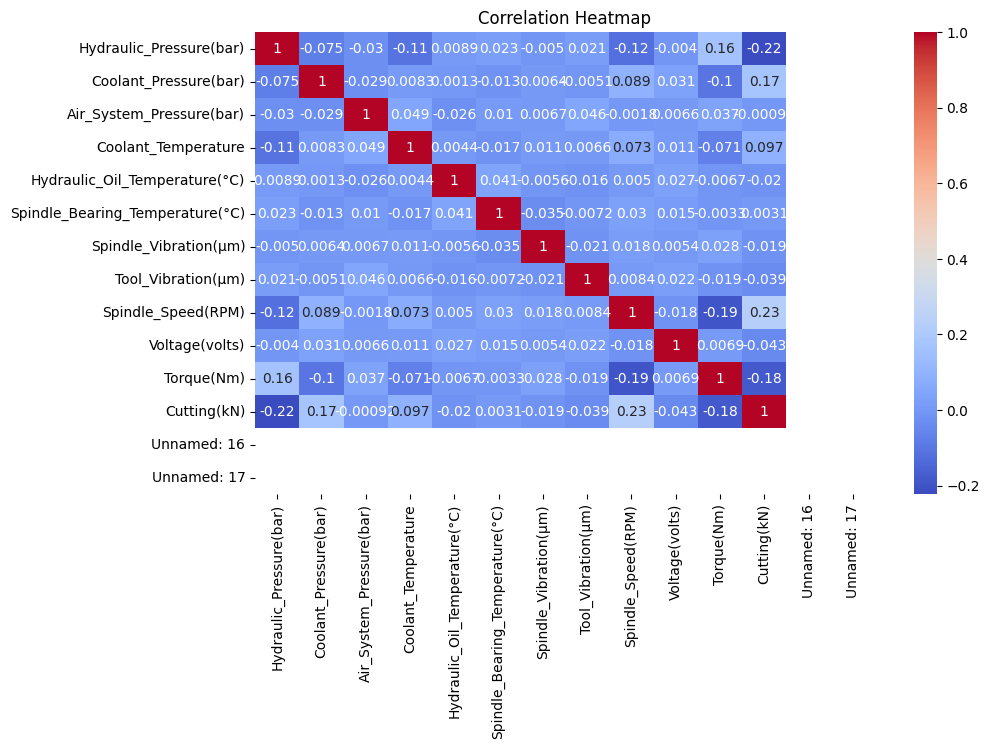

In [ ]:
# Heatmaps
plt.figure(figsize=(10, 6))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
# Create a pie chart for Assembly_Line_No
assembly_line_counts = df['Assembly_Line_No'].value_counts()

plt.figure(figsize=(8, 8))

plt.subplot(1, 2, 1)
plt.pie(assembly_line_counts, labels=assembly_line_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Proportion of Different Assembly Lines')

# Create a pie chart for Machine_ID
machine_id_counts = df['Machine_ID'].value_counts()

plt.subplot(1, 2, 2)
plt.pie(machine_id_counts, labels=machine_id_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Proportion of Different Machines')

plt.tight_layout()
plt.show()


In [ ]:
# Inference : It shows the % Machine_Failure and No_Machine_Failure
# Pie chart for Downtime distribution
downtime_counts = df['Downtime'].value_counts()
plt.figure(figsize=(3, 3))
plt.pie(downtime_counts, labels=downtime_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Downtime')
plt.show()


In [ ]:
# Inference : Strip plots show data distribution and density, highlighting variations and outliers. They offer a quick visual comparison.
# Create a strip plot for a specific feature
plt.figure(figsize=(10, 6))
sns.stripplot(data=df, x='Assembly_Line_No', y='Hydraulic_Pressure(bar)', jitter=True)
plt.title('Hydraulic Pressure by Assembly Line')
plt.xlabel('Assembly Line Number')
plt.ylabel('Hydraulic Pressure (bar)')
plt.grid(True)

plt.show()


In [ ]:
# Inference : A Q-Q plot checks if your data fits a normal distribution. Points close to the line indicate normality, otherwise deviations.

# List of columns to plot
columns_to_plot = [
    'Hydraulic_Pressure(bar)',
    'Coolant_Pressure(bar)',
    'Air_System_Pressure(bar)',
    'Spindle_Speed(RPM)',
    'Voltage(volts)'
]
# Create Q-Q plots for the specified columns
plt.figure(figsize=(14, 10))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(len(columns_to_plot), 2, i)
    stats.probplot(df[column].dropna(), dist="norm", plot=plt)
    plt.title(f'Q-Q Plot of {column}', fontsize=12)
    plt.xlabel('Theoretical Quantiles')
    plt.ylabel('Sample Quantiles')

plt.tight_layout()
plt.show()


In [ ]:
 # Inference : Violin plots reveal the distribution and density of the data, highlighting the central tendency and spread of each feature.
 # They also help identify any outliers and provide a clear visual comparison across categories.
 # List of columns to plot
columns_to_plot = [
    'Hydraulic_Pressure(bar)',
    'Coolant_Pressure(bar)',
    'Air_System_Pressure(bar)',
    'Spindle_Speed(RPM)',
    'Voltage(volts)'
]

# Create violin plots for the specified columns
plt.figure(figsize=(10, 12))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(len(columns_to_plot), 4, i)
    sns.violinplot(data=df, y=column)
    plt.title(f'Violin Plot of {column}', fontsize=10)
    plt.xlabel('Density', fontsize=10)
    plt.ylabel(column, fontsize=10)
    plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:


# Select the column for which you want to create the density plot
data = df['Hydraulic_Pressure(bar)']

# Create the density plot
plt.figure(figsize=(4, 2))
sns.kdeplot(data, shade=True, color='blue')
plt.title('Density Plot')
plt.xlabel('Hydraulic_Pressure(bar)')
plt.ylabel('Density')
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# Inference : A density plot helps you visualize the distribution of a single variable.
# It shows the shape, central tendency, spread, and any potential outliers in the data.

# Select the columns for which you want to create the density plots
columns_to_plot = [
    'Hydraulic_Pressure(bar)',
    'Coolant_Pressure(bar)',
    'Air_System_Pressure(bar)',
    'Spindle_Speed(RPM)'
]
# Create a density plot for each column
plt.figure(figsize=(8, 4))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 2, i)  # Create a subplot for each density plot
    sns.kdeplot(df[column], shade=True)
    plt.title(f'Density Plot of {column}')
    plt.xlabel(column)
    plt.ylabel('Density')
    plt.grid(True)

plt.tight_layout()
plt.show()
